# inicializando funcoes

In [1]:
import math
import numpy
import numpy as np
import matplotlib.pyplot as plt
import modules.SimulacaoKTz as ktzsim

# Define function for string formatting of scientific notation
def sci_notation(num, decimal_digits=1, precision=None, exponent=None):
    """
    Returns a string representation of the scientific
    notation of the given number formatted for use with
    LaTeX or Mathtext, with specified number of significant
    decimal digits and precision (number of decimal digits
    to show). The exponent to be used can also be specified
    explicitly.
    """
    if exponent is None:
        exponent = int(math.floor(math.log10(abs(num))))
    coeff = round(num / float(10**exponent), decimal_digits)
    if precision is None:
        precision = decimal_digits
    if coeff != 1.0:
        return r"{0:.{2}f}\cdot10^{{{1:d}}}".format(coeff, exponent, precision)
    return r"10^{{{0:d}}}".format(exponent)

def select_rows(X,n_rows):
    return X[np.floor(np.linspace(0,X.shape[0]-1,n_rows)).astype(int),:]

def select_cols(X,n_cols):
    return X[:,np.floor(np.linspace(0,X.shape[0]-1,n_cols)).astype(int)]

def select_elem(X,n_el):
    return X[np.floor(np.linspace(0,X.shape[0]-1,n_el)).astype(int)]

def delete_elem(X,x):
    k = np.nonzero(X==x)[0]
    if k.size > 0:
        return np.delete(X,k)
    return X

# temperatura dinamica homeostatica

## K=0

d:\Dropbox\p\ufsc\pesquisa\simulacoes\mapa_ktz_py\modules\SimulacaoKTz.py:232: NumbaExperimentalFeatureWarning: First-class function type feature is experimental
  for t in range(t_transiente):


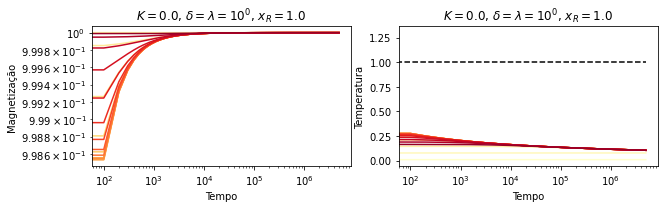

In [2]:

plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 0.0
d     = 1.0 #0.001
l     = 1.0 #0.001
xR    = Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,1.3,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktctanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()

## K=0.2

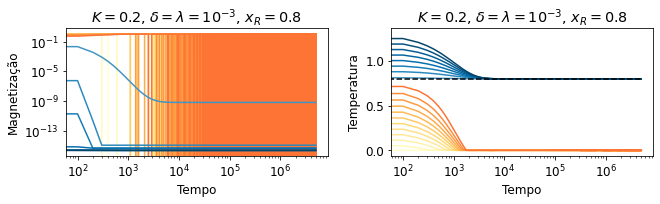

In [3]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 0.2
d     = 0.001
l     = 0.001
xR    = Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,1.3,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktctanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()

## K=0.3

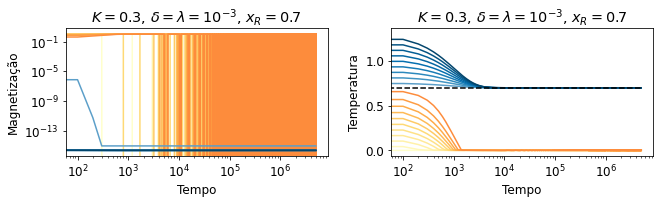

In [27]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 0.3
d     = 0.001
l     = 0.001
xR    = Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,1.3,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktctanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()

## K=0.5

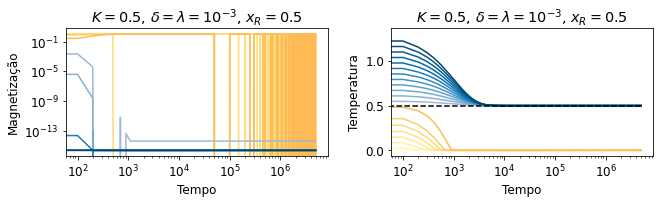

In [28]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 0.5
d     = 0.001
l     = 0.001
xR    = Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,1.3,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktctanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()

## K=0.6

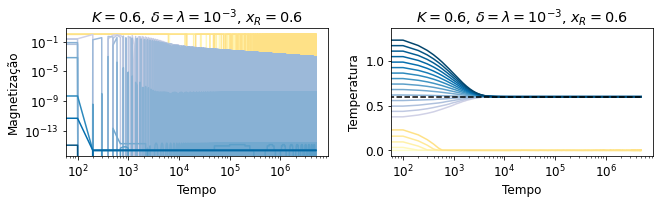

In [29]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 0.6
d     = 0.001
l     = 0.001
xR    = Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,1.3,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktctanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()

## K=1.5

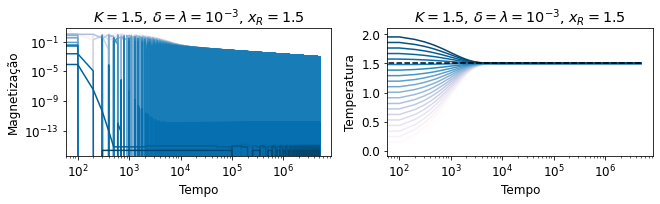

In [30]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 1.5
d     = 0.001
l     = 0.001
xR    = Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,2.0,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktctanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta=\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()

# temperatura dinamica abs(m)

## K=0

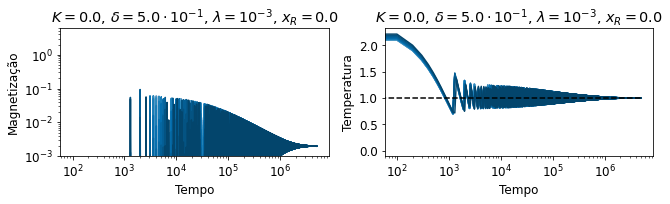

In [ ]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 0.0
d     = 0.001
l     = 0.1
xR    = 0.0#1e-6#Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,1.3,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktcabstanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())


ax[0].set_ylim(bottom=1e-3)

plt.tight_layout()

plt.show()

## K=0.2

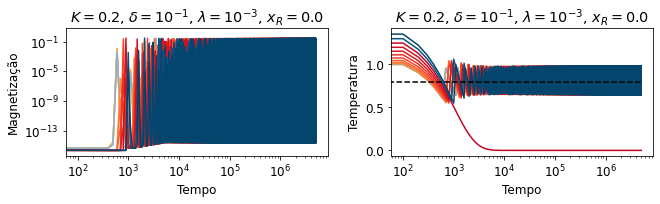

In [10]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 0.2
d     = 0.001
l     = 0.1
xR    = 0.0#1e-6#Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,1.3,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktcabstanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()

## K=0.3

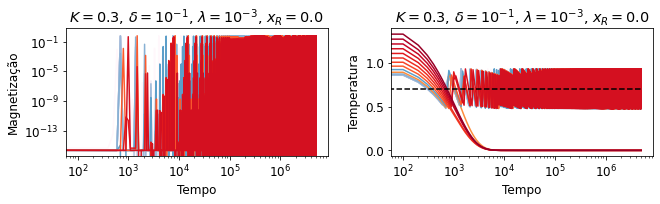

In [12]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 0.3
d     = 0.001
l     = 0.1
xR    = 0.0#1e-6#Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,1.3,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktcabstanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()

## K=0.5

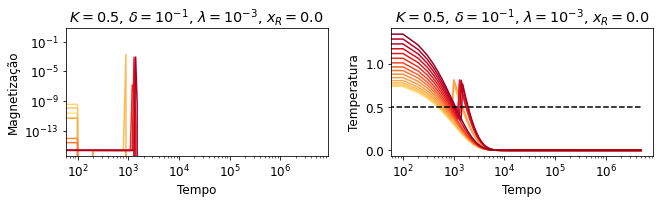

In [14]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 0.5
d     = 0.001
l     = 0.1
xR    = 0.0#1e-6#Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,1.3,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktcabstanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()

## K=0.6

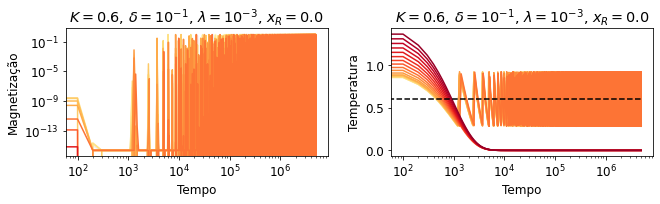

In [15]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 0.6
d     = 0.001
l     = 0.1
xR    = 0.0#1e-6#Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,1.3,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktcabstanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()

## K=1.5

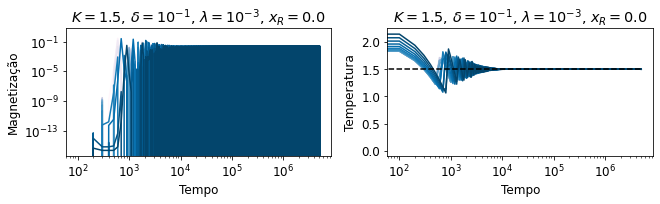

In [16]:
plt.rcParams.update({'font.size':12})

Tc_func  = lambda K: 1.0-K if K<0.5 else K

K     = 1.5
d     = 0.001
l     = 0.1
xR    = 0.0#1e-6#Tc_func(K)*d/l
H     = 0.0

# precisao de convergence para Tc
epsilon = 1e-1

###########################
###########################
###########################
########################### rodando para varias temperaturas iniciais
###########################
###########################
###########################

# valores iniciais de temperatura ignorando T_max (que deve ser obtido dinamicamente)
T0_valores = delete_elem(np.linspace(0.01,2.0,20),Tc_func(K)) #[ 0.8, 0.9, 1.1, 1.2 ]
# condicoes iniciais fixas
m0     = 1.0
y0     = 1.0


t_transiente = 0
t_total      = 5000000
num_t_plot   = 50000
x_dados = []
for T0 in T0_valores:
    x0 = numpy.array((m0,y0,T0),dtype=numpy.float64)
    x  = ktzsim.RodaSimulacaoMapa(K,T0,d,l,xR,H,0.0,0.0,t_transiente,t_total,x0,'ktcabstanh')
    x_dados.append(x[:,:4])
    x_dados[-1] = select_rows(numpy.delete(x_dados[-1], 1, axis=1), num_t_plot) # deleting column corresponding to y


# x_dados[i] -> corresponde a temperatura inicial T0_valores[i]
#               x_dados[i][:,0] -> magnetizacao
#               x_dados[i][:,1] -> temperatura
#               x_dados[i][:,2] -> susceptibilidade


fig,ax = plt.subplots(nrows=1,ncols=2,sharex=True,figsize=(9.3333,3))

line_color_good = plt.get_cmap('PuBu')
line_color_bad  = plt.get_cmap('YlOrRd')

t_dados = select_elem(np.arange(t_total-t_transiente+1),num_t_plot)
for i,T0 in enumerate(T0_valores):
    if abs(x_dados[i][-1,1] - Tc_func(K)) <= epsilon:
        color = line_color_good(i/len(T0_valores))
    else:
        color = line_color_bad(i/len(T0_valores))
    ax[0].plot(t_dados,x_dados[i][:,0],label=f'T_0={T0}',c=color)
    ax[1].plot(t_dados,x_dados[i][:,1],label=f'T_0={T0}',c=color)


ax[0].set_xlabel('Tempo')
ax[1].set_xlabel('Tempo')

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_yscale('log')
#ax[1].set_yscale('log')

ax[1].hlines(Tc_func(K), -1, t_total+1, linestyle='--', color='k')

ax[0].set_ylabel('Magnetização')
ax[1].set_ylabel('Temperatura')

ax[0].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')
ax[1].set_title(f'$K={K}$, $\\delta={sci_notation(l)}$, $\\lambda={sci_notation(d)}$, $x_R={xR}$')

#ax[1].set_yticklabels(ax[1].get_yticks())

plt.tight_layout()

plt.show()